In [133]:
%load_ext autoreload
%autoreload 2

from fsl_mrs.utils.synthetic import synthetic_from_dynamic as syn
from fsl_mrs.utils import mrs_io
from fsl_mrs.utils import plotting as splot

import matplotlib.pyplot as plt
import pandas as pd
import re
import numpy as np
basis = mrs_io.read_basis('basis')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Load the two direction files 

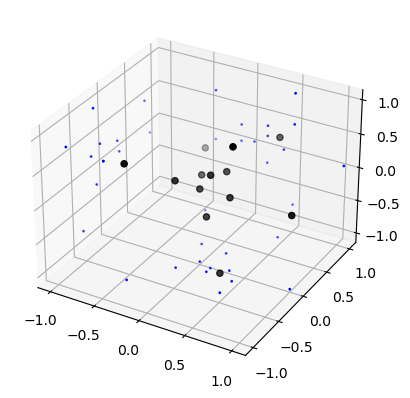

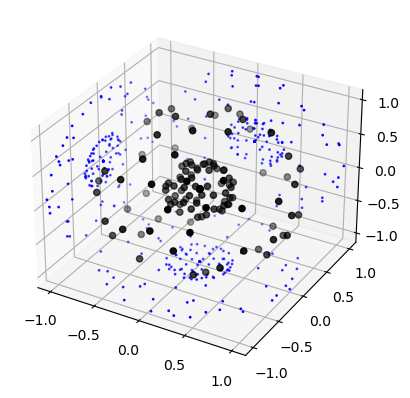

In [134]:
def load_file(file_path, max_bvalue=3, plot=True):
    bvecs = []
    bvptrn = re.compile(r'Vector\[\d+\] = \((.*)\)')
    with open(file_path) as bv:
        for line in bv.readlines():
            match = bvptrn.match(line)
            if match:
                bvecs.append([float(x) for x in match[1].split(',')])
    bvecs = np.asarray(bvecs)

    if plot:
        fig = plt.figure()
        ax = fig.add_subplot(projection='3d')
        ax.scatter(bvecs[:,0], bvecs[:,1], -1.1 + 0*bvecs[:,2], c='b', s=1)
        ax.scatter(bvecs[:,0], 1.1 + 0*bvecs[:,1], bvecs[:,2], c='b', s=1)
        ax.scatter(-1.1 + 0*bvecs[:,0], bvecs[:,1], bvecs[:,2], c='b', s=1)
        ax.scatter(bvecs[:,0], bvecs[:,1], bvecs[:,2], c='k')
        ax.set_xlim([-1.1, 1.1])
        ax.set_ylim([-1.1, 1.1])
        ax.set_zlim([-1.1, 1.1])
        plt.show()

    return bvecs * max_bvalue

# B values in units of s/mm^2
b_6_dir =load_file('b_1000_3000_6dir', max_bvalue=3000, plot=True)
b_60_dir =load_file('b_1000_3000_60dir', max_bvalue=3000, plot=True)




### Generate ball and sticks parameters

's0', 'd', 'th1', 'ph1', 'f1', 'th2', 'ph2', 'f2'  
s + f1 + f2 = 1

In [135]:
def get_metabolite_bs_params(metab, adc_mean, adc_sd):
    rng = np.random.default_rng()
    adc = 0
    while adc <= 0:
        adc = adc_mean + rng.standard_normal(1) * adc_sd
    if metab == 'NAA':
        # NAA is equally in two crossing fibres
        return {\
            f'conc_{metab}_d': adc[0],
            f'conc_{metab}_th1': np.pi/2,
            f'conc_{metab}_ph1': 0,
            f'conc_{metab}_f1': 0.5,
            f'conc_{metab}_th2': np.pi/2,
            f'conc_{metab}_ph2': np.pi/2,
            f'conc_{metab}_f2': 0.5}

    elif metab == 'Ins':
        # Ins is in astrocytes, mostly non-directional
        return {\
            f'conc_{metab}_d': adc[0],
            f'conc_{metab}_th1': np.pi/2,
            f'conc_{metab}_ph1': 0,
            f'conc_{metab}_f1': 0.1,
            f'conc_{metab}_th2': 0,
            f'conc_{metab}_ph2': 0,
            f'conc_{metab}_f2': 0.00}
    elif metab == 'Cr':
        # Mix of above
        return {\
            f'conc_{metab}_d': adc[0],
            f'conc_{metab}_th1': np.pi/2,
            f'conc_{metab}_ph1': 0,
            f'conc_{metab}_f1': 0.25,
            f'conc_{metab}_th2': np.pi/2,
            f'conc_{metab}_ph2': np.pi/2,
            f'conc_{metab}_f2': 0.25}

    else:
        raise ValueError(f'{metab} Metabolite not recognised')

diffusivity_mean = 2E-4  # in mm^2/s (to match s/mm^2 b values)
diffusivity_sd = 2E-5  # in mm^2/s (to match s/mm^2 b values)

print(get_metabolite_bs_params('NAA', diffusivity_mean, diffusivity_sd)) 

{'conc_NAA_d': 0.00020551699849522654, 'conc_NAA_th1': 1.5707963267948966, 'conc_NAA_ph1': 0, 'conc_NAA_f1': 0.5, 'conc_NAA_th2': 1.5707963267948966, 'conc_NAA_ph2': 1.5707963267948966, 'conc_NAA_f2': 0.5}


### Generate data for each set of directions and the precomputed random tensors

Noise variance for the 6 direction data should be 10 times less than the 60 direction, to match total experiment time.

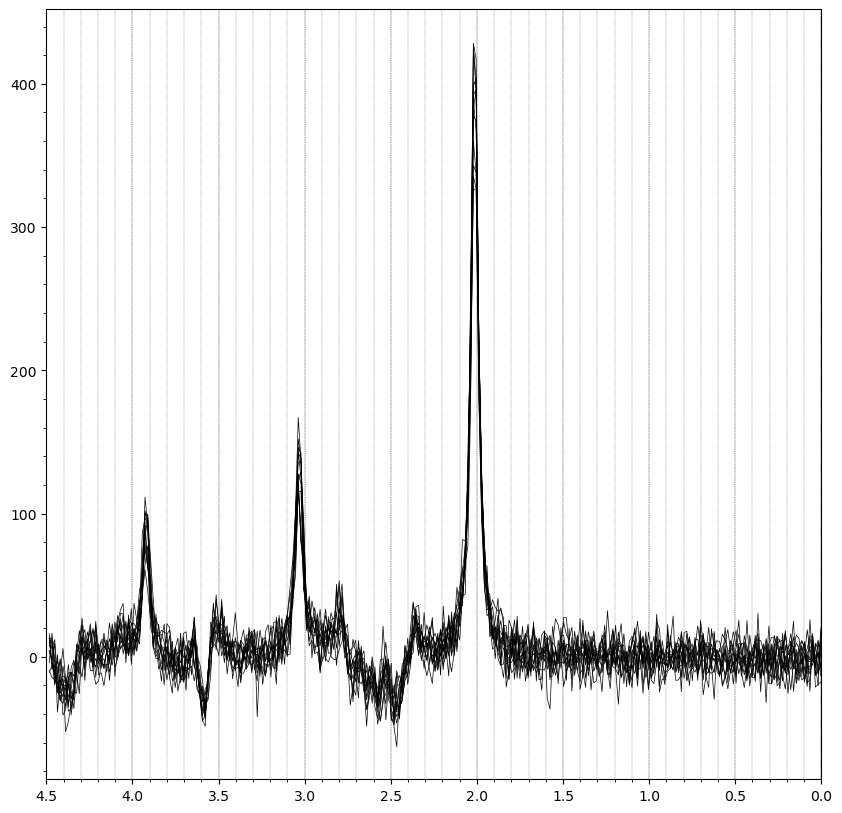

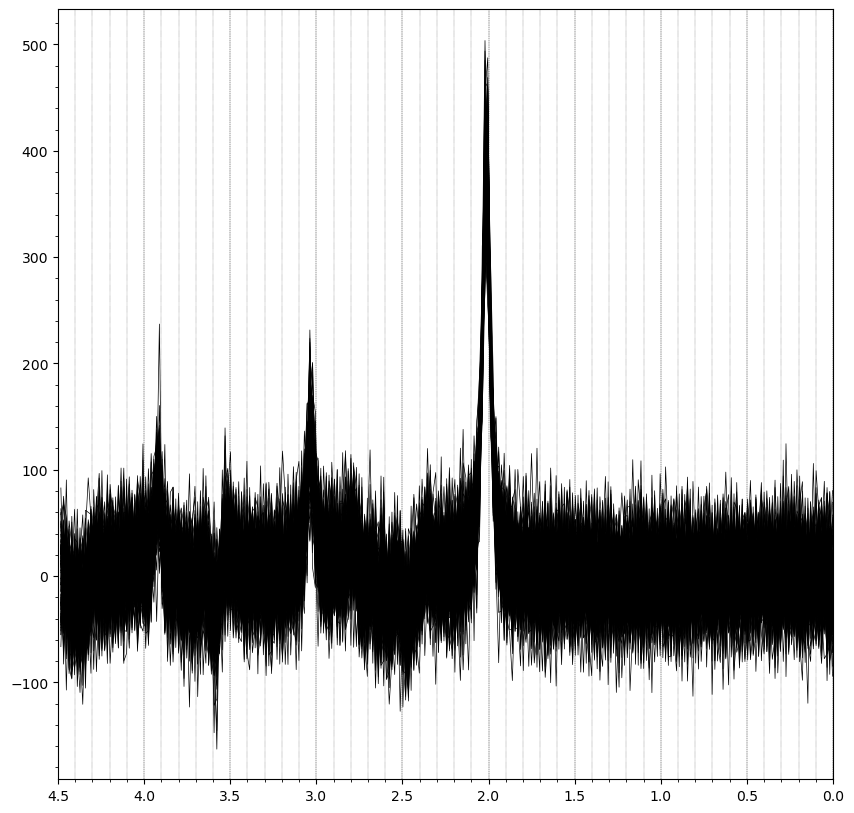

In [136]:
ignore_metabs = ['Tau', 'Scyllo', 'PE', 'PCr', 'PCh', 'NAAG', 'Lac', 'Gln', 'Glc', 'GSH', 'GPC', 'Asp', 'Asc', 'Ala', 'GABA', 'Glu']

def generate_dataset(directions, noisevar, defined_values):

    mrs_list, vm_obj, ground_truth = syn.synthetic_spectra_from_model(
        'model_ball2sticks.py',
        directions,
        'basis',
        ignore=ignore_metabs,
        metab_groups=None,
        ind_scaling=None,
        concentrations=None,
        baseline_order=0,
        baseline_ppm=None,
        defined_vals=defined_vals,
        param_noise=None,
        param_rel_noise=None,
        noisecovariance=[[noisevar]],
        bandwidth=2000,
        points=1024
    )

    _ = splot.plot_spectra(mrs_list, plot_avg=False)
    truth_df = pd.Series(ground_truth, index=vm_obj.free_names)
    return mrs_list, truth_df

from fsl_mrs.utils.synthetic.synthetic_from_basis import standardConcentrations
std_concs = standardConcentrations(basis.names)

defined_vals = {
    'gamma_0': 16,
    'sigma_0': 0
}
for name, conc in zip(basis.get_formatted_names(ignore_metabs), std_concs):
    defined_vals[f'conc_{name}_c_S0'] = conc
    defined_vals.update(get_metabolite_bs_params(name, diffusivity_mean, diffusivity_sd))

mrs_list_6, truth_df_6 = generate_dataset(b_6_dir, 100, defined_vals)
mrs_list_60, truth_df_60 = generate_dataset(b_60_dir, 1000, defined_vals)

In [137]:
from fsl_mrs.dynamic import dynMRS

fit_args = {'model': 'lorentzian',
            'ppmlim': (0.2, 4.2),
            'baseline_order': 0}

# Create the dynamic fitting object
dyn_6 = dynMRS(mrs_list_6, b_6_dir, config_file='model_ball2sticks.py', rescale=False, **fit_args)

# Initialise the fit.
init_6 = dyn_6.initialise(verbose=True, indiv_init='mean')

dyn_res_6 = dyn_6.fit(init=init_6, verbose=True, method='Newton')

Init done in 4.201509952545166 seconds.
Start fitting
...completed in 0.7436459064483643 seconds.
Collect results
...completed in 0.3782970905303955 seconds.


In [138]:
# Create the dynamic fitting object
dyn_60 = dynMRS(mrs_list_60, b_60_dir, config_file='model_ball2sticks.py', rescale=False, **fit_args)

# Initialise the fit.
init_60 = dyn_60.initialise(verbose=True, indiv_init='mean')

dyn_res_60 = dyn_60.fit(init=init_60, verbose=True, method='Newton')

Init done in 38.83928394317627 seconds.
Start fitting
...completed in 73.64273715019226 seconds.
Collect results
...completed in 3.9812428951263428 seconds.


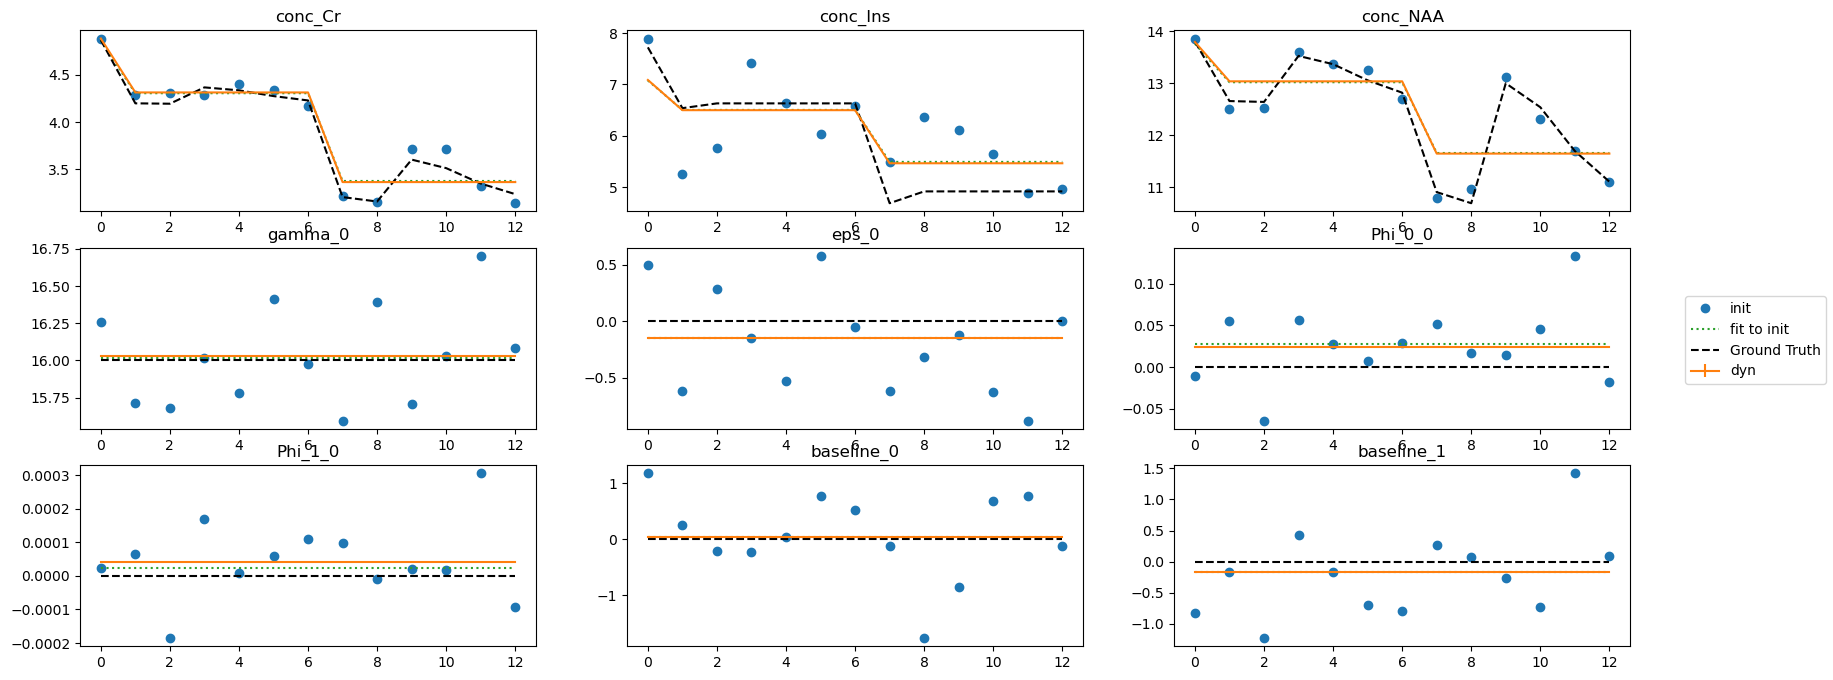

In [139]:
fig = dyn_res_6.plot_mapped(tvals=np.arange(b_6_dir.shape[0]), fit_to_init=True, ground_truth=truth_df_6.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

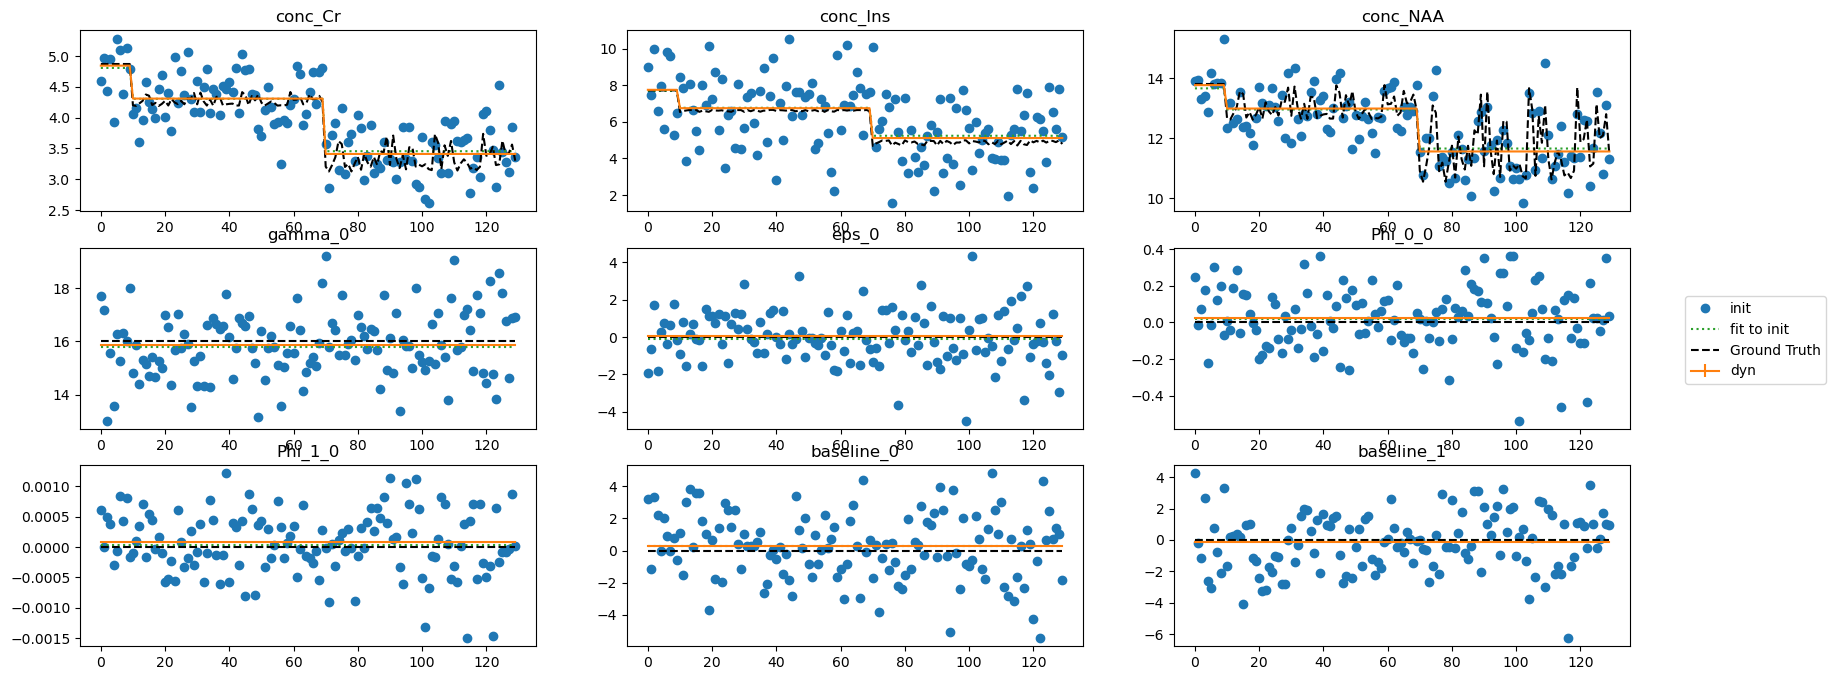

In [140]:
fig = dyn_res_60.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=True, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [141]:
comp_df = pd.concat([truth_df_60.drop('sigma_0'), dyn_res_6.dataframe_free.T[0], dyn_res_60.dataframe_free.T[0]], axis=1, keys=['true', '6_dir', '60_dir'])
comp_df.style.format('{:.2g}')

,true,6_dir,60_dir
conc_Cr_s0,4.9,4.9,4.8
conc_Cr_d,0.0002,0.00012,0.00012
conc_Cr_th1,1.6,0,0
conc_Cr_ph1,0,0,0
conc_Cr_f1,0.25,0,0
conc_Cr_th2,1.6,0,0
conc_Cr_ph2,1.6,0,0
conc_Cr_f2,0.25,0,0
conc_Ins_s0,7.7,7.1,7.8
conc_Ins_d,0.00017,8.7e-05,0.00014


### Perfect initialisation

Start fitting
...completed in 97.52221918106079 seconds.
Collect results
...completed in 3.2654268741607666 seconds.


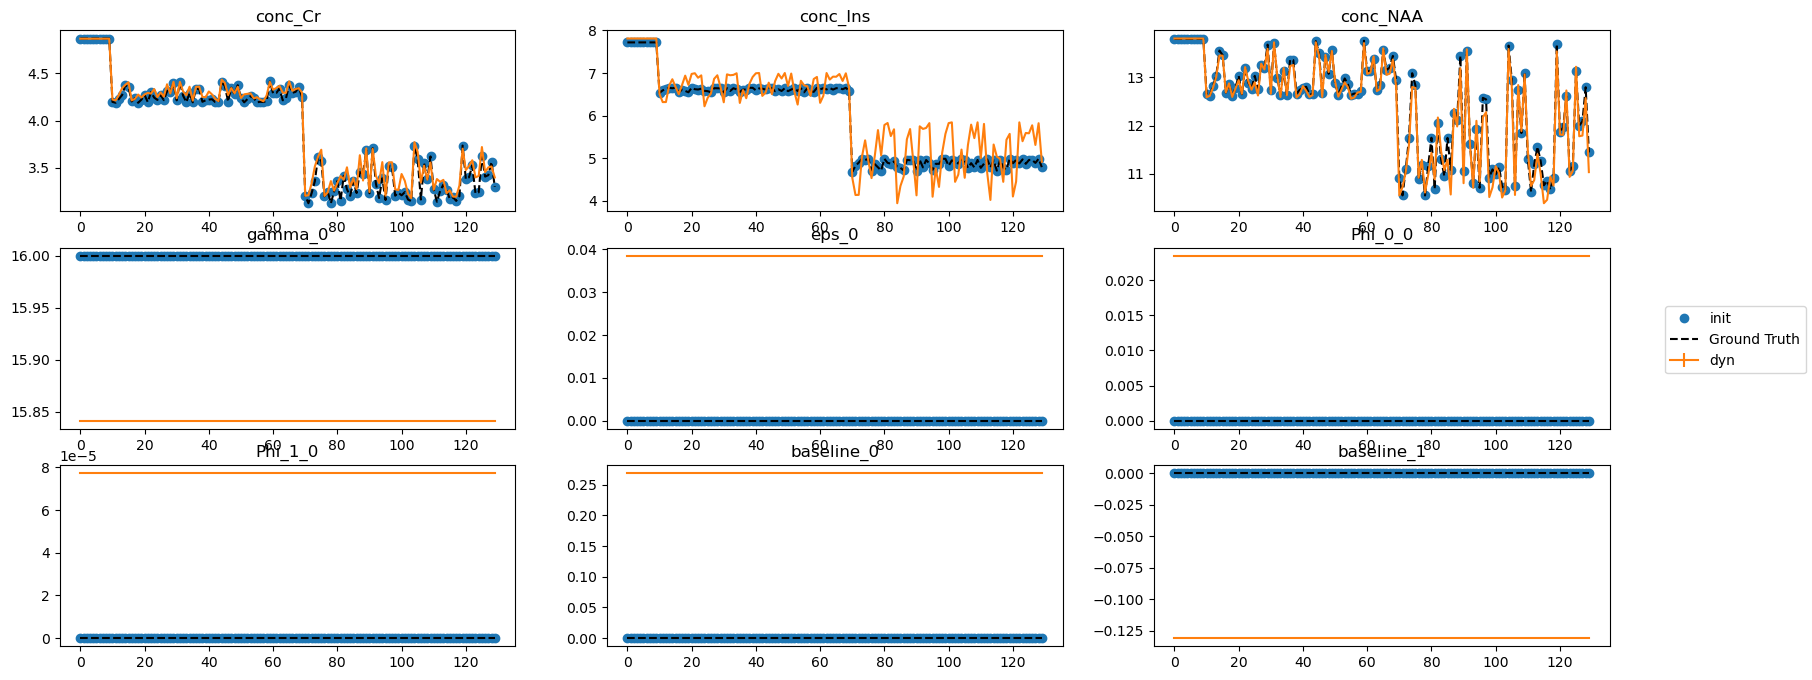

In [142]:
dyn_res_perfect = dyn_60.fit(x0=truth_df_60.drop('sigma_0').to_numpy(), verbose=True, method='Newton')
fig = dyn_res_perfect.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=False, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [143]:
comp_df = pd.concat([truth_df_60.drop('sigma_0'), dyn_res_6.dataframe_free.T[0], dyn_res_60.dataframe_free.T[0], dyn_res_perfect.dataframe_free.T[0]], axis=1, keys=['true', '6_dir', '60_dir', 'perfect'])
comp_df.style.format('{:.2g}')  

,true,6_dir,60_dir,perfect
conc_Cr_s0,4.9,4.9,4.8,4.9
conc_Cr_d,0.0002,0.00012,0.00012,0.00018
conc_Cr_th1,1.6,0,0,1.7
conc_Cr_ph1,0,0,0,-0.6
conc_Cr_f1,0.25,0,0,0.28
conc_Cr_th2,1.6,0,0,1.4
conc_Cr_ph2,1.6,0,0,0.98
conc_Cr_f2,0.25,0,0,0.19
conc_Ins_s0,7.7,7.1,7.8,7.8
conc_Ins_d,0.00017,8.7e-05,0.00014,0.00023


## xfibres initilisation

In [144]:
from fsl.data.image import Image
from fsl.wrappers.wrapperutils import fileOrImage, fslwrapper, applyArgStyle, SHOW_IF_TRUE, LOAD
from pathlib import Path 

def run_xfiber_init(init_obj, bval, bvec):
    init_concs = init_obj['mapped_params']['conc']
    init_concs = init_concs.reshape((init_concs.shape[0], 1, 1, init_concs.shape[-1]))
    concs_image = Image(init_concs)
    mask_image = Image(np.ones(concs_image.shape[:-1]))
    # concs_image.save('tmp_concs')
    # mask_image.save('tmp_concsmask')

    @fileOrImage('data', 'mask', 'out')
    @fslwrapper
    def xfibres(data, mask, bvecs, bvals, **kwargs):
        cmd  = ['xfibres',
                f'--data={data}',
                f'--mask={mask}',
                f'--bvecs={bvecs}',
                f'--bvals={bvals}']
        full_cmd = cmd + applyArgStyle('--=', valmap={'verbose': SHOW_IF_TRUE, 'forcedir': SHOW_IF_TRUE}, **kwargs)
        print(' '.join(full_cmd))
        return full_cmd

    logdir = Path('tmp_xfibers_out')

    xfibres(concs_image, mask_image, bval, bvec, nf=2, verbose=False, ld=str(logdir), forcedir=True)

    xfibre_out = {
        'f1': 'mean_f1samples.nii.gz',
        'f2': 'mean_f2samples.nii.gz',
        'd':  'mean_dsamples.nii.gz',
        's0': 'mean_S0samples.nii.gz',
        'ph1': 'ph1samples.nii.gz',
        'ph2': 'ph2samples.nii.gz',
        'th1': 'th1samples.nii.gz',
        'th2': 'th2samples.nii.gz'}
    xfibre_res = {}

    for key, value in xfibre_out.items():
        tmp_data = Image(logdir / value)[:].squeeze()
        if tmp_data.ndim>1:
            tmp_data = tmp_data.mean(axis=1)
        xfibre_res.update({key: tmp_data})
    xfiber_init_df = pd.DataFrame(xfibre_res, index=dyn_60.metabolite_names)
    xfiber_init_df[xfiber_init_df.abs() > 1E3] = 0
    return xfiber_init_df

d60_xinit = run_xfiber_init(init_60, 'b_1000_3000_60dir.bvec', 'b_1000_3000_60dir.bval')
d6_xinit = run_xfiber_init(init_6, 'b_1000_3000_6dir.bvec', 'b_1000_3000_6dir.bval')


xfibres --data=/var/folders/m_/wrzz00910m1drlc1vxl3n2n00000gn/T/tmpy1r4tz4y/tmp2lkq96zl.nii.gz --mask=/var/folders/m_/wrzz00910m1drlc1vxl3n2n00000gn/T/tmpy1r4tz4y/tmpaqtzzts2.nii.gz --bvecs=b_1000_3000_60dir.bvec --bvals=b_1000_3000_60dir.bval --nf=2 --ld=tmp_xfibers_out --forcedir
Log directory is: tmp_xfibers_out
1/3
2/3
3/3
xfibres --data=/var/folders/m_/wrzz00910m1drlc1vxl3n2n00000gn/T/tmpl8uwztkt/tmpse5ffsja.nii.gz --mask=/var/folders/m_/wrzz00910m1drlc1vxl3n2n00000gn/T/tmpl8uwztkt/tmpii4w4ifd.nii.gz --bvecs=b_1000_3000_6dir.bvec --bvals=b_1000_3000_6dir.bval --nf=2 --ld=tmp_xfibers_out --forcedir
Log directory is: tmp_xfibers_out
1/3
2/3
3/3


In [145]:
d60_xinit.style.format('{:.2g}') 

,f1,f2,d,s0,ph1,ph2,th1,th2
Cr,0.14,1.9e-07,0.00012,4.8,0,0,-1.2,0
Ins,0.32,6.6e-07,0.00018,7.7,-36,0,8.7,0
NAA,0.5,0.46,0.00017,14,1.4,-0.19,1.5,1.5


In [146]:
d6_xinit.style.format('{:.2g}') 

,f1,f2,d,s0,ph1,ph2,th1,th2
Cr,0.23,8.1e-06,0.00015,4.9,-15,0,-10,0
Ins,0.5,0.00039,0.00013,7.1,-3.8e+02,0,4.5,0
NAA,0.4,8.5e-08,7.4e-05,14,0,0,3.2,0


Start fitting
...completed in 6.43099308013916 seconds.
Collect results
...completed in 0.36902403831481934 seconds.


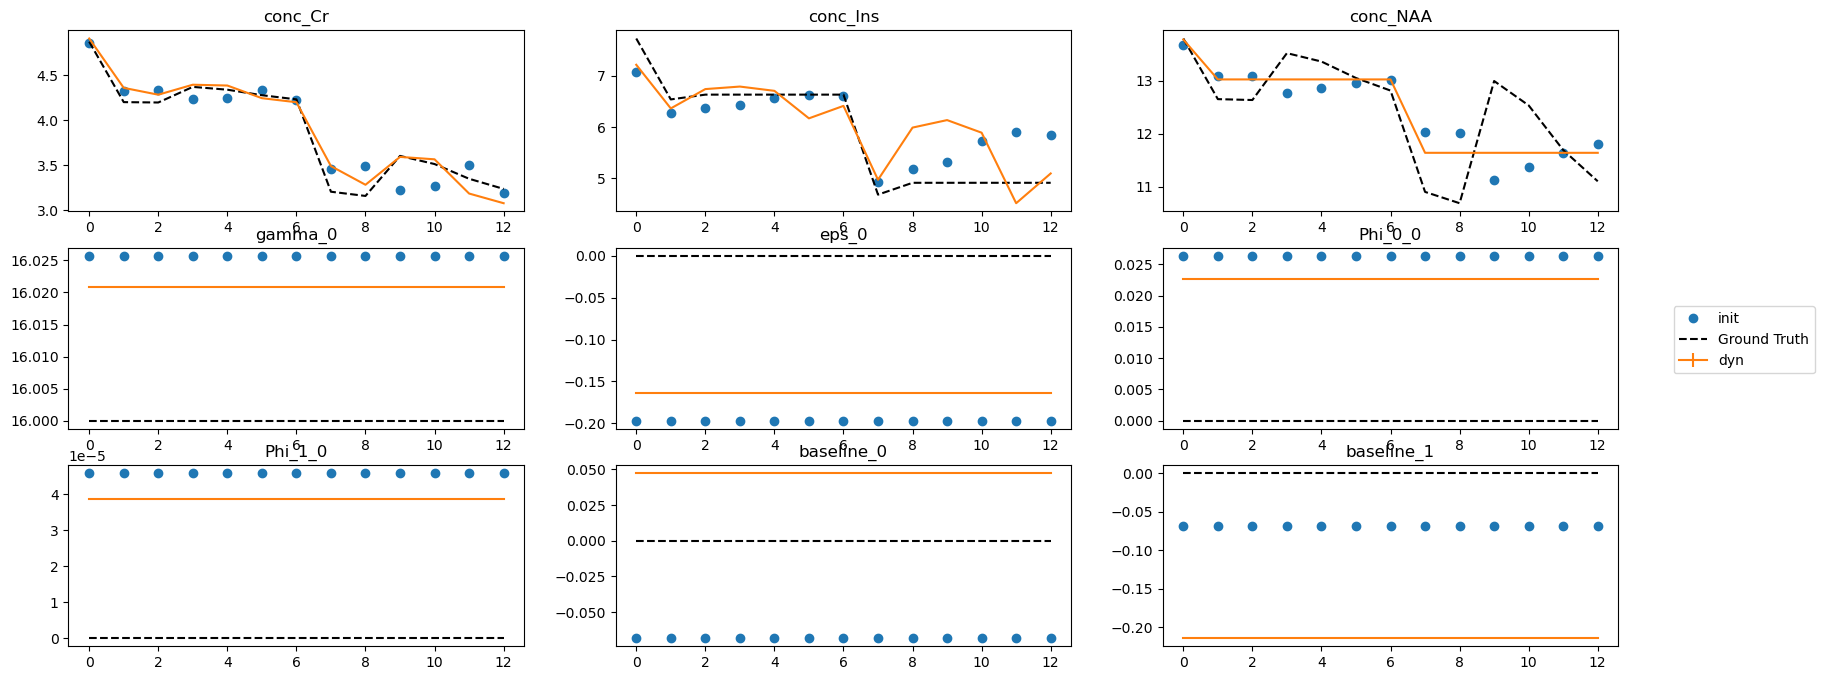

In [147]:
# Convert init output to an appropriate input for init
xfiber_init_aray = []
for val in dyn_res_6.dataframe_free.squeeze().index:
    if 'conc' in val:
        _, metab, param = val.split('_')
        xfiber_init_aray.append(d6_xinit.loc[metab, param])
    else:
        valsplit = val.split('_')
        new_val = '_'.join(valsplit[:-1])
        xfiber_init_aray.append(init_6['mapped_params'][new_val].mean())
xfiber_init_aray = np.asarray(xfiber_init_aray)
dyn_res_6_xfiber = dyn_6.fit(x0=xfiber_init_aray, verbose=True, method='Newton')
fig = dyn_res_6_xfiber.plot_mapped(tvals=np.arange(b_6_dir.shape[0]), fit_to_init=False, ground_truth=truth_df_6.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

Start fitting
...completed in 83.27343273162842 seconds.
Collect results
...completed in 2.923023223876953 seconds.


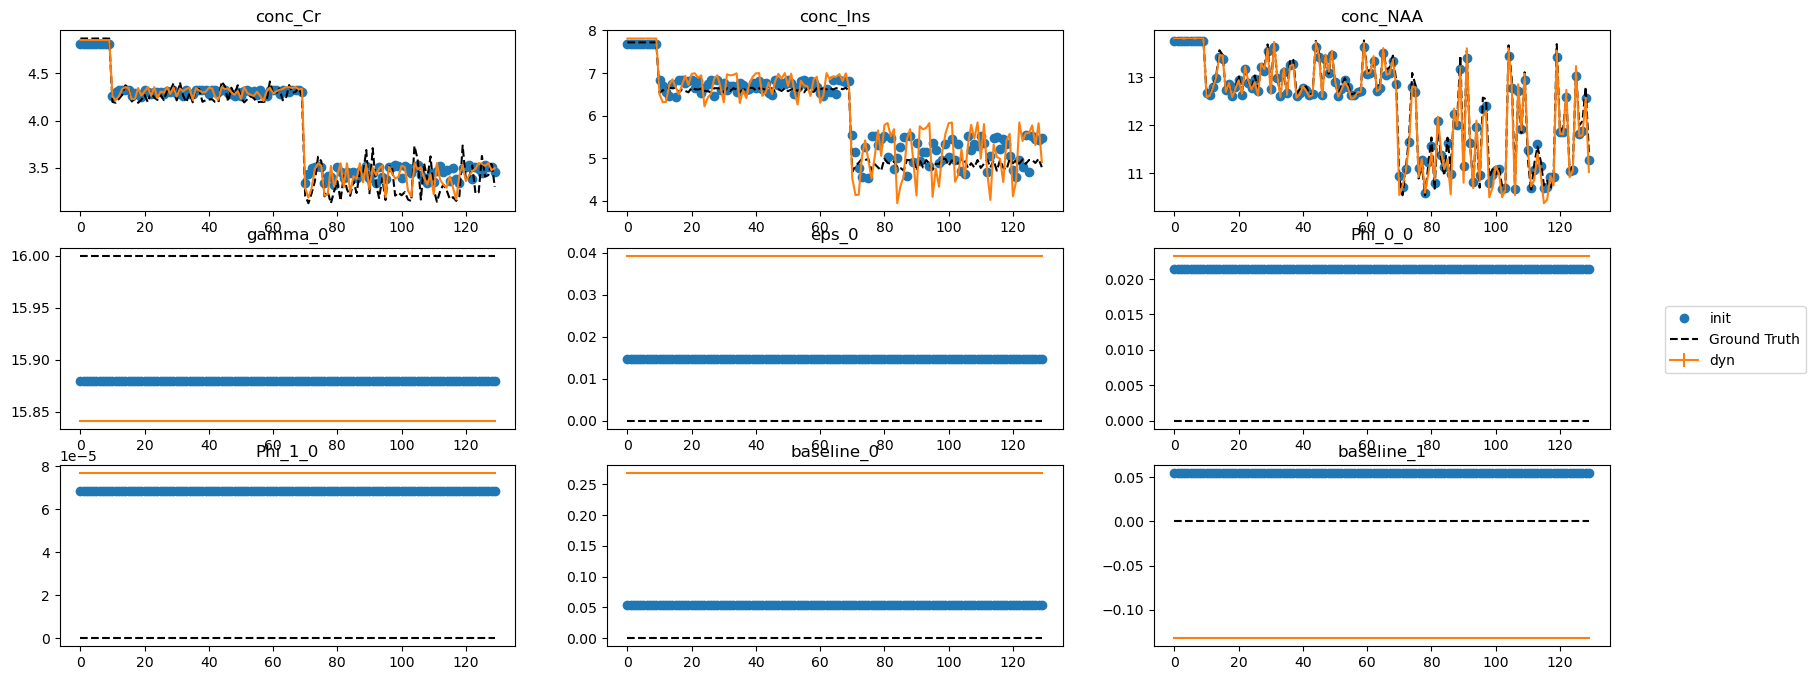

In [148]:
# Convert init output to an appropriate input for init
xfiber_init_aray = []
for val in dyn_res_60.dataframe_free.squeeze().index:
    if 'conc' in val:
        _, metab, param = val.split('_')
        xfiber_init_aray.append(d60_xinit.loc[metab, param])
    else:
        valsplit = val.split('_')
        new_val = '_'.join(valsplit[:-1])
        xfiber_init_aray.append(init_60['mapped_params'][new_val].mean())
xfiber_init_aray = np.asarray(xfiber_init_aray)
dyn_res_xfiber = dyn_60.fit(x0=xfiber_init_aray, verbose=True, method='Newton')
fig = dyn_res_xfiber.plot_mapped(tvals=np.arange(b_60_dir.shape[0]), fit_to_init=False, ground_truth=truth_df_60.drop('sigma_0').to_numpy())
fig.set_size_inches(20, 8)

In [149]:
comp_df = pd.concat([truth_df_60.drop('sigma_0'), dyn_res_6_xfiber.dataframe_free.T[0], dyn_res_xfiber.dataframe_free.T[0]], axis=1, keys=['true', '6_dir', '60_dir', 'perfect'])
comp_df.style.format('{:.2g}')  

,true,6_dir,60_dir
conc_Cr_s0,4.9,4.9,4.9
conc_Cr_d,0.0002,0.00017,0.00014
conc_Cr_th1,1.6,-11,-1.5
conc_Cr_ph1,0,-15,-0.63
conc_Cr_f1,0.25,0.32,0.23
conc_Cr_th2,1.6,-2.9e-11,-6.1e-11
conc_Cr_ph2,1.6,1.3e-22,-1.6e-21
conc_Cr_f2,0.25,0,0
conc_Ins_s0,7.7,7.2,7.8
conc_Ins_d,0.00017,0.00018,0.00023
